In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

REVIEWS_PATH = Path("../data/raw/reviews.csv")

In [2]:
reviews_sample = pd.read_csv(REVIEWS_PATH, nrows=5)

print("Nombre de colonnes :", len(reviews_sample.columns))

for i, col in enumerate(reviews_sample.columns, 1):
    print(f"{i}. {col}")

print("\nTypes :")
print(reviews_sample.dtypes)

Nombre de colonnes : 8
1. ReviewId
2. RecipeId
3. AuthorId
4. AuthorName
5. Rating
6. Review
7. DateSubmitted
8. DateModified

Types :
ReviewId          int64
RecipeId          int64
AuthorId          int64
AuthorName       object
Rating            int64
Review           object
DateSubmitted    object
DateModified     object
dtype: object


In [3]:
total_reviews = 0

for chunk in pd.read_csv(REVIEWS_PATH, chunksize=50000):
    total_reviews += len(chunk)

print("Nombre total de reviews :", total_reviews)

Nombre total de reviews : 1401982


In [4]:
missing_counts = {}

for chunk in pd.read_csv(REVIEWS_PATH, chunksize=50000):
    for col in chunk.columns:
        missing_counts[col] = missing_counts.get(col, 0) + chunk[col].isna().sum()

missing_df = pd.DataFrame({
    "missing_count": missing_counts
})

missing_df["missing_percentage"] = (
    missing_df["missing_count"] / total_reviews * 100
)

missing_df.sort_values(
    "missing_percentage",
    ascending=False
)

,missing_count,missing_percentage
Review,214,0.015264
ReviewId,0,0.000000
AuthorId,0,0.000000
RecipeId,0,0.000000
AuthorName,0,0.000000
Rating,0,0.000000
DateSubmitted,0,0.000000
DateModified,0,0.000000


In [5]:
numeric_columns_reviews = reviews_sample.select_dtypes(
    include=np.number
).columns.tolist()

print(numeric_columns_reviews)

['ReviewId', 'RecipeId', 'AuthorId', 'Rating']


In [6]:
missing_counts = {}

for chunk in pd.read_csv(REVIEWS_PATH, chunksize=50000):
    for col in chunk.columns:
        missing_counts[col] = missing_counts.get(col, 0) + chunk[col].isna().sum()

missing_df = pd.DataFrame({
    "missing_count": missing_counts
})

missing_df["missing_percentage"] = (
    missing_df["missing_count"] / total_reviews * 100
)

missing_df.sort_values(
    "missing_percentage",
    ascending=False
)

,missing_count,missing_percentage
Review,214,0.015264
ReviewId,0,0.000000
AuthorId,0,0.000000
RecipeId,0,0.000000
AuthorName,0,0.000000
Rating,0,0.000000
DateSubmitted,0,0.000000
DateModified,0,0.000000


In [7]:
ratings = []

for chunk in pd.read_csv(
    REVIEWS_PATH,
    usecols=["Rating"],
    chunksize=50000
):
    ratings.extend(
        pd.to_numeric(
            chunk["Rating"],
            errors="coerce"
        ).dropna().tolist()
    )

ratings = np.array(ratings)

Q1 = np.percentile(ratings, 25)
Q3 = np.percentile(ratings, 75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ratings[
    (ratings < lower_bound) |
    (ratings > upper_bound)
]

print("Q1 :", Q1)
print("Q3 :", Q3)
print("Borne inférieure :", lower_bound)
print("Borne supérieure :", upper_bound)
print("Nombre d'outliers :", len(outliers))
print("Pourcentage :", len(outliers) / len(ratings) * 100)

Q1 : 4.0
Q3 : 5.0
Borne inférieure : 2.5
Borne supérieure : 6.5
Nombre d'outliers : 110404
Pourcentage : 7.874851460289791


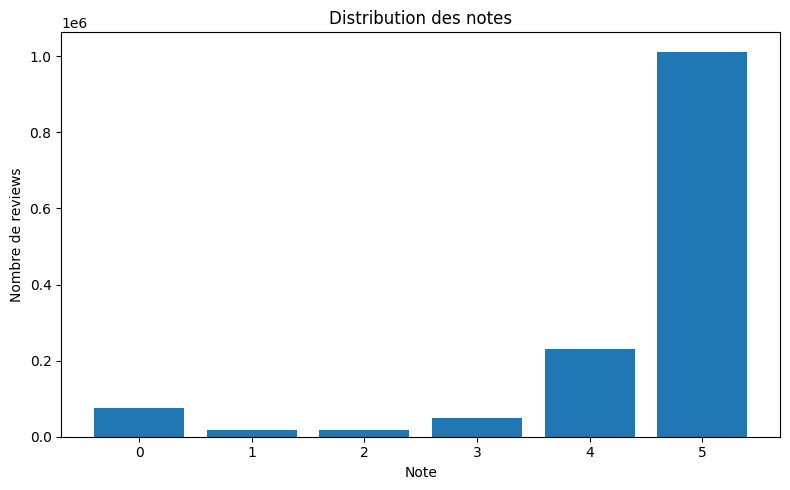

In [8]:
rating_counts = {}

for chunk in pd.read_csv(
    REVIEWS_PATH,
    usecols=["Rating"],
    chunksize=50000
):
    counts = chunk["Rating"].value_counts()

    for rating, count in counts.items():
        rating_counts[rating] = (
            rating_counts.get(rating, 0) + count
        )

rating_df = pd.DataFrame(
    list(rating_counts.items()),
    columns=["Rating", "Count"]
).sort_values("Rating")

plt.figure(figsize=(8, 5))

plt.bar(
    rating_df["Rating"].astype(str),
    rating_df["Count"]
)

plt.xlabel("Note")
plt.ylabel("Nombre de reviews")
plt.title("Distribution des notes")

plt.tight_layout()
plt.show()

In [9]:
user_review_counts = {}

for chunk in pd.read_csv(
    REVIEWS_PATH,
    usecols=["AuthorId"],
    chunksize=50000
):
    counts = chunk["AuthorId"].value_counts()

    for user_id, count in counts.items():
        user_review_counts[user_id] = (
            user_review_counts.get(user_id, 0) + count
        )

user_counts = pd.Series(user_review_counts)

print("Nombre d'utilisateurs :", len(user_counts))
print("Nombre moyen de reviews par utilisateur :", user_counts.mean())
print("Médiane :", user_counts.median())
print("Maximum :", user_counts.max())

Nombre d'utilisateurs : 271907
Nombre moyen de reviews par utilisateur : 5.156108522399203
Médiane : 1.0
Maximum : 8842


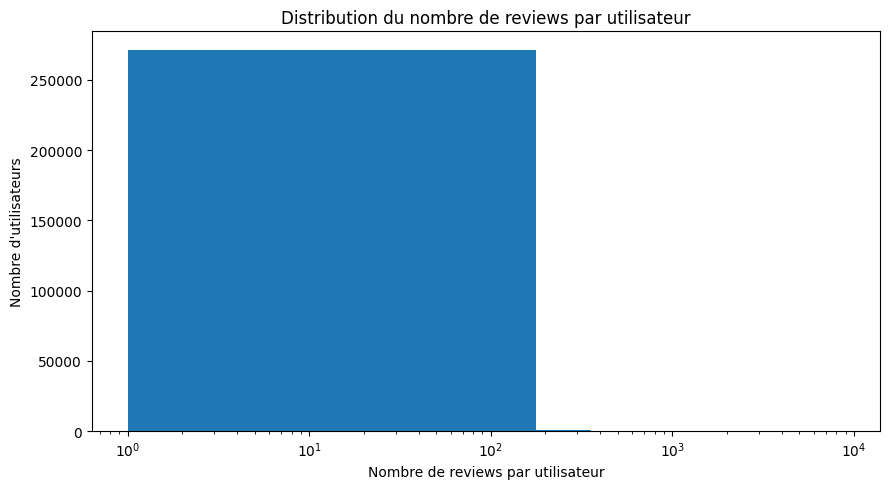

In [10]:
plt.figure(figsize=(9, 5))

plt.hist(
    user_counts,
    bins=50
)

plt.xlabel("Nombre de reviews par utilisateur")
plt.ylabel("Nombre d'utilisateurs")
plt.title("Distribution du nombre de reviews par utilisateur")
plt.xscale("log")

plt.tight_layout()
plt.show()

In [11]:
recipe_review_counts = {}

for chunk in pd.read_csv(
    REVIEWS_PATH,
    usecols=["RecipeId"],
    chunksize=50000
):
    counts = chunk["RecipeId"].value_counts()

    for recipe_id, count in counts.items():
        recipe_review_counts[recipe_id] = (
            recipe_review_counts.get(recipe_id, 0) + count
        )

recipe_counts = pd.Series(recipe_review_counts)

print("Nombre de recettes ayant au moins une review :", len(recipe_counts))
print("Nombre moyen de reviews par recette :", recipe_counts.mean())
print("Médiane :", recipe_counts.median())
print("Maximum :", recipe_counts.max())

Nombre de recettes ayant au moins une review : 271678
Nombre moyen de reviews par recette : 5.160454655879387
Médiane : 2.0
Maximum : 2892


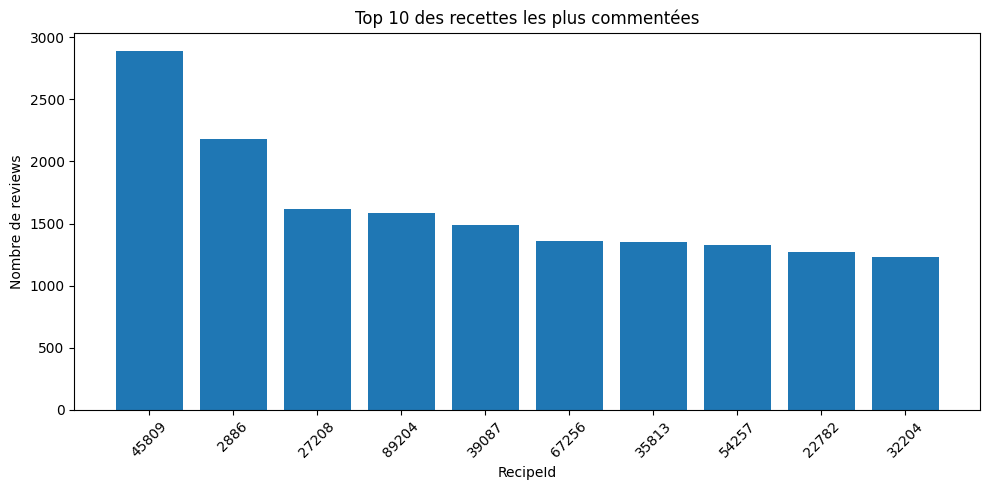

In [12]:
top_recipes = recipe_counts.sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top_recipes.index.astype(str),
    top_recipes.values
)

plt.xlabel("RecipeId")
plt.ylabel("Nombre de reviews")
plt.title("Top 10 des recettes les plus commentées")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [14]:
unique_interactions = set()

for chunk in pd.read_csv(
    REVIEWS_PATH,
    usecols=["AuthorId", "RecipeId"],
    chunksize=50000
):
    interactions = zip(
        chunk["AuthorId"],
        chunk["RecipeId"]
    )

    unique_interactions.update(interactions)

print(
    "Nombre d'interactions utilisateur-recette uniques :",
    len(unique_interactions)
)

Nombre d'interactions utilisateur-recette uniques : 1401982


In [15]:
num_users = len(user_counts)
num_recipes = len(recipe_counts)
num_interactions = len(unique_interactions)

total_possible = num_users * num_recipes

sparsity = 1 - (num_interactions / total_possible)

print("Nombre d'utilisateurs :", num_users)
print("Nombre de recettes :", num_recipes)
print("Interactions :", num_interactions)
print("Interactions possibles :", total_possible)
print("Sparsité :", sparsity * 100, "%")

Nombre d'utilisateurs : 271907
Nombre de recettes : 271678
Interactions : 1401982
Interactions possibles : 73871149946
Sparsité : 99.99810212511782 %


In [1]:
import pandas as pd
from pathlib import Path

REVIEWS_PATH = Path("../data/processed/reviews_clean.csv")

df = pd.read_csv(REVIEWS_PATH)

print("Répartition des notes :")
display(df["Rating"].value_counts(dropna=False).sort_index())

print("Exemples de notes hors intervalle 1-5 :")
display(
    df.loc[
        ~df["Rating"].between(1, 5),
        ["ReviewId", "RecipeId", "Rating", "Review"]
    ].head(20)
)

Répartition des notes :


Rating
0      76248
1      16559
2      17597
3      50279
4     229217
5    1012082
Name: count, dtype: int64

Exemples de notes hors intervalle 1-5 :


,ReviewId,RecipeId,Rating,Review
7,21,148,0,Would someone please check the Nutrition Facts...
34,73,2502,0,Unusual name for a recipe that has no pumpkin ...
47,91,4165,0,I thought Chicken Cacciatore had peppers. If i...
56,109,2505,0,Terrible directions. Doesn't say how to make t...
76,138,4048,0,makes 2- 9inch pies or 1 deep dish pie
92,157,316,0,"This is in fact not a Greek dish, but Turkish...."
93,158,4213,0,"Baklava is definitely not Greek, but Turkish. ..."
94,159,3722,0,"This dish, with slight variations (usually lem..."
111,185,8468,0,I''m really happy to read so many people are e...
113,188,3137,0,the finished product is excellent.
